# Etapa 3 — Avaliação e Camada de Decisão

Cálculo das métricas de classificação no conjunto de teste, ajuste dos limiares de prioridade **exclusivamente na validação** (privilegiando Recall >= 0,90 da classe ALTERADA) e conversão de `p(alterada)` nas 5 saídas do sistema.

In [1]:
import os
import sys
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir('..')
ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

from src.config import RESULTS_DIR
from src.decision import OUTPUTS, RECALL_TARGET, Thresholds, decide_many, fit_thresholds
from src.evaluation import binary_metrics, subgroup_metrics, threshold_for_recall

sns.set_theme(style='whitegrid')
(RESULTS_DIR / 'metrics').mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / 'figures').mkdir(parents=True, exist_ok=True)

## 1. Carga das predições e ajuste dos limiares na validação

In [2]:
pred_dir = RESULTS_DIR / 'predictions'
base_val = pd.read_csv(pred_dir / 'baseline_validation.csv')
base_test = pd.read_csv(pred_dir / 'baseline_test.csv')
res_val = pd.read_csv(pred_dir / 'resnet50_validation.csv')
res_test = pd.read_csv(pred_dir / 'resnet50_test.csv')

for name, df in [('base_val', base_val), ('base_test', base_test), ('res_val', res_val), ('res_test', res_test)]:
    print(f'{name}: {len(df)} amostras | ALTERADA={(df.label == 1).sum()} ({(df.label == 1).mean():.1%})')

th_resnet = fit_thresholds(res_val['label'], res_val['p_alterada'])
th_resnet.to_json(RESULTS_DIR / 'thresholds.json')

t_rotina_base = threshold_for_recall(base_val['label'], base_val['p_alterada'], RECALL_TARGET)

print('\nLimiares ResNet-50 (salvos em results/thresholds.json):', th_resnet)
print(f'Limiar t_rotina Baseline (meta recall={RECALL_TARGET:.2f}): {t_rotina_base:.6f}')

base_val: 531 amostras | ALTERADA=227 (42.7%)
base_test: 1144 amostras | ALTERADA=530 (46.3%)
res_val: 531 amostras | ALTERADA=227 (42.7%)
res_test: 1144 amostras | ALTERADA=530 (46.3%)



Limiares ResNet-50 (salvos em results/thresholds.json): Thresholds(t_rotina=0.23111643, t_alta=0.7878209, margin=0.05)
Limiar t_rotina Baseline (meta recall=0.90): 0.455231


## 2. Métricas globais no teste (`t_rotina` vs. referência `0,5`)

In [3]:
rows_overall = [
    {'modelo': 'baseline', 'limiar': t_rotina_base, **binary_metrics(base_test['label'], base_test['p_alterada'], t_rotina_base)},
    {'modelo': 'resnet50', 'limiar': th_resnet.t_rotina, **binary_metrics(res_test['label'], res_test['p_alterada'], th_resnet.t_rotina)},
]
df_overall = pd.DataFrame(rows_overall)
df_overall.to_csv(RESULTS_DIR / 'metrics' / 'test_overall.csv', index=False)
print('=== Teste com limiar t_rotina ajustado na validação ===')
display(df_overall)

rows_05 = [
    {'modelo': 'baseline', 'limiar': 0.5, **binary_metrics(base_test['label'], base_test['p_alterada'], 0.5)},
    {'modelo': 'resnet50', 'limiar': 0.5, **binary_metrics(res_test['label'], res_test['p_alterada'], 0.5)},
]
print('=== Referência no teste com limiar 0,5 ===')
display(pd.DataFrame(rows_05))

=== Teste com limiar t_rotina ajustado na validação ===


,modelo,limiar,recall,precision,f1,balanced_accuracy,specificity,auroc,pr_auc,tp,tn,fp,fn,n
0,baseline,0.455231,0.854717,0.484492,0.61843,0.534850,0.214984,0.537011,0.488947,453,132,482,77,1144
1,resnet50,0.231116,0.903774,0.543084,0.67847,0.623711,0.343648,0.724703,0.660541,479,211,403,51,1144


=== Referência no teste com limiar 0,5 ===


,modelo,limiar,recall,precision,f1,balanced_accuracy,specificity,auroc,pr_auc,tp,tn,fp,fn,n
0,baseline,0.5,0.216981,0.493562,0.301442,0.512399,0.807818,0.537011,0.488947,115,496,118,415,1144
1,resnet50,0.5,0.550943,0.688679,0.612159,0.667980,0.785016,0.724703,0.660541,292,482,132,238,1144


## 3. Matriz de confusão (ResNet-50) e curvas ROC / Precision-Recall

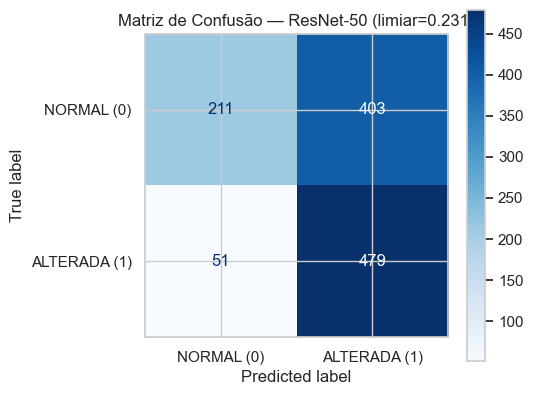

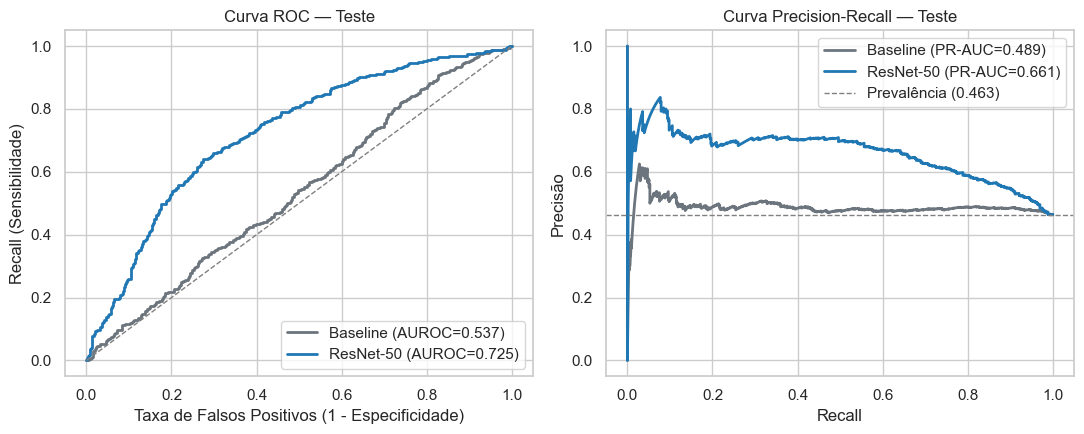

In [4]:
y_pred_res = (res_test['p_alterada'] >= th_resnet.t_rotina).astype(int)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    res_test['label'],
    y_pred_res,
    display_labels=['NORMAL (0)', 'ALTERADA (1)'],
    cmap='Blues',
    ax=ax,
    values_format='d',
)
ax.set_title(f'Matriz de Confusão — ResNet-50 (limiar={th_resnet.t_rotina:.3f})')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'figures' / 'confusao_resnet50.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for label_name, df_m, color in [
    ('Baseline', base_test, '#6c757d'),
    ('ResNet-50', res_test, '#1f77b4'),
]:
    m_ref = binary_metrics(df_m['label'], df_m['p_alterada'], 0.5)
    fpr, tpr, _ = roc_curve(df_m['label'], df_m['p_alterada'])
    axes[0].plot(fpr, tpr, label=f"{label_name} (AUROC={m_ref['auroc']:.3f})", color=color, lw=2)
    prec, rec, _ = precision_recall_curve(df_m['label'], df_m['p_alterada'])
    axes[1].plot(rec, prec, label=f"{label_name} (PR-AUC={m_ref['pr_auc']:.3f})", color=color, lw=2)

axes[0].plot([0, 1], [0, 1], '--', color='gray', lw=1)
axes[0].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
axes[0].set_ylabel('Recall (Sensibilidade)')
axes[0].set_title('Curva ROC — Teste')
axes[0].legend(loc='lower right')

prevalence = res_test['label'].mean()
axes[1].axhline(prevalence, ls='--', color='gray', lw=1, label=f'Prevalência ({prevalence:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precisão')
axes[1].set_title('Curva Precision-Recall — Teste')
axes[1].legend(loc='upper right')

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'figures' / 'roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## 4. Desempenho por subgrupo no teste (ResNet-50)

In [5]:
sub_frames = []
for col in ['sex', 'age_group', 'view']:
    sub = subgroup_metrics(res_test, col, th_resnet.t_rotina)
    sub.insert(0, 'variavel', col)
    sub_frames.append(sub)

df_subgroups = pd.concat(sub_frames, ignore_index=True)
df_subgroups.to_csv(RESULTS_DIR / 'metrics' / 'test_subgroups.csv', index=False)
display(df_subgroups)

,variavel,group,recall,precision,f1,balanced_accuracy,specificity,auroc,pr_auc,tp,tn,fp,fn,n
0,sex,F,0.922449,0.559406,0.696456,0.610831,0.299213,0.722754,0.683221,226,76,178,19,499
1,sex,M,0.887719,0.529289,0.663172,0.631360,0.375000,0.726559,0.647092,253,135,225,32,645
2,age_group,18-39,0.885714,0.546256,0.675749,0.670370,0.455026,0.765457,0.662417,124,86,103,16,329
3,age_group,40-59,0.901288,0.557029,0.688525,0.631941,0.362595,0.735839,0.695175,210,95,167,23,495
4,age_group,60+,0.927007,0.542735,0.684636,0.551965,0.176923,0.663504,0.640755,127,23,107,10,267
5,age_group,<18,0.900000,0.409091,0.562500,0.556061,0.212121,0.648485,0.601364,18,7,26,2,53
6,view,AP,0.971660,0.592593,0.736196,0.589195,0.206731,0.729893,0.719669,240,43,165,7,455
7,view,PA,0.844523,0.501048,0.628947,0.629158,0.413793,0.701413,0.602038,239,168,238,44,689


## 5. Camada de decisão e faixas de prioridade no teste

,saida,normal,alterada,total,pct_alteradas
0,IMAGEM INADEQUADA,0,0,0,0.000000
1,INDETERMINADO,134,54,188,10.188679
2,PRIORIDADE ALTA,8,36,44,6.792453
3,PRIORIDADE MÉDIA,319,406,725,76.603774
4,ROTINA,153,34,187,6.415094


Recall de PRIORIDADE ALTA + MÉDIA: 0.8340 (442/530)
ALTERADAS em INDETERMINADO: 54 (10.19%)
ALTERADAS em ROTINA: 34 (6.42%)


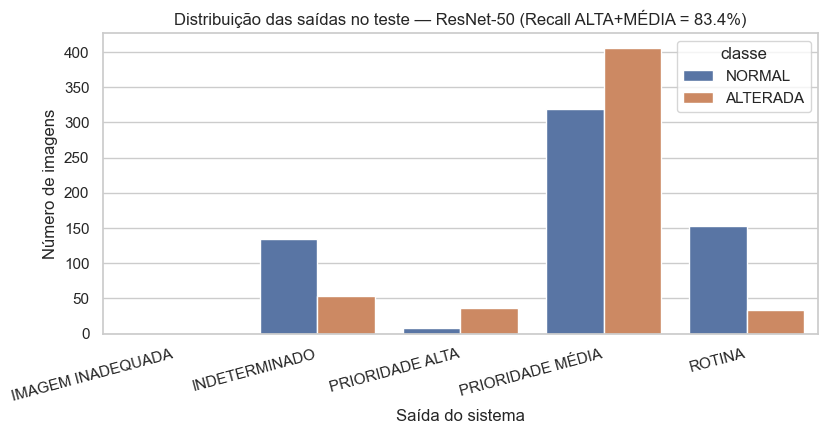

In [6]:
res_test_dec = res_test.copy()
res_test_dec['saida'] = decide_many(res_test_dec['p_alterada'], th_resnet)

total_alteradas = int((res_test_dec['label'] == 1).sum())
priority_rows = []
for saida in OUTPUTS:
    sub = res_test_dec[res_test_dec['saida'] == saida]
    n_norm = int((sub['label'] == 0).sum())
    n_alt = int((sub['label'] == 1).sum())
    priority_rows.append({
        'saida': saida,
        'normal': n_norm,
        'alterada': n_alt,
        'total': len(sub),
        'pct_alteradas': (n_alt / total_alteradas * 100.0) if total_alteradas else 0.0,
    })

df_priority = pd.DataFrame(priority_rows)
df_priority.to_csv(RESULTS_DIR / 'metrics' / 'test_priority.csv', index=False)
display(df_priority)

alt_alta_media = df_priority.loc[
    df_priority['saida'].isin(['PRIORIDADE ALTA', 'PRIORIDADE MÉDIA']), 'alterada'
].sum()
recall_alta_media = alt_alta_media / total_alteradas if total_alteradas else 0.0
alt_indet = int(df_priority.loc[df_priority['saida'] == 'INDETERMINADO', 'alterada'].sum())
alt_rotina = int(df_priority.loc[df_priority['saida'] == 'ROTINA', 'alterada'].sum())
print(f'Recall de PRIORIDADE ALTA + MÉDIA: {recall_alta_media:.4f} ({alt_alta_media}/{total_alteradas})')
print(f'ALTERADAS em INDETERMINADO: {alt_indet} ({alt_indet/total_alteradas:.2%})')
print(f'ALTERADAS em ROTINA: {alt_rotina} ({alt_rotina/total_alteradas:.2%})')

plot_df = df_priority.melt(id_vars='saida', value_vars=['normal', 'alterada'],
                           var_name='classe', value_name='imagens')
plot_df['classe'] = plot_df['classe'].map({'normal': 'NORMAL', 'alterada': 'ALTERADA'})
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.barplot(data=plot_df, x='saida', y='imagens', hue='classe',
            order=list(OUTPUTS), palette={'NORMAL': '#4c72b0', 'ALTERADA': '#dd8452'}, ax=ax)
ax.set_xlabel('Saída do sistema')
ax.set_ylabel('Número de imagens')
ax.set_title(f'Distribuição das saídas no teste — ResNet-50 (Recall ALTA+MÉDIA = {recall_alta_media:.1%})')
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'figures' / 'prioridade.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. Conclusões

1. **Ganho da ResNet-50 sobre o baseline:** com o limiar `t_rotina` ajustado exclusivamente na validação para meta de Recall >= 0,90 (`0,2311` na ResNet-50 e `0,4552` no baseline), a ResNet-50 superou o baseline em todas as métricas globais no teste: **AUROC** passou de `0,5370` para `0,7247` (+0,1877), **PR-AUC** de `0,4889` para `0,6605` (+0,1716), **Balanced Accuracy** de `0,5349` para `0,6237`, **Recall** de `0,8547` para `0,9038`, **Precisão** de `0,4845` para `0,5431` e **F1-score** de `0,6184` para `0,6785` (reduzindo os falsos negativos de 77 para 51 e aumentando os verdadeiros negativos de 132 para 211 em 1.144 imagens).
2. **Meta de 90% de Recall no teste:** na avaliação binária em `t_rotina = 0,2311`, a ResNet-50 manteve a meta no conjunto de teste com **Recall = 0,9038** (479/530 exames alterados). Na camada de 5 saídas, considerando a faixa de incerteza `INDETERMINADO` (`|p - t_rotina| < 0,05`), **PRIORIDADE ALTA + PRIORIDADE MÉDIA** somaram **83,40% de Recall** (442/530), sendo 36 casos em `PRIORIDADE ALTA` (com precisão de 81,82% na faixa, acima da meta de 80% com `t_alta = 0,7878`) e 406 em `PRIORIDADE MÉDIA`. Outras **54 imagens alteradas (10,19%)** caíram em `INDETERMINADO`, de modo que apenas **34 imagens alteradas (6,42%)** foram enviadas para `ROTINA`.
3. **Subgrupos com pior desempenho:**
   - **Incidência (`view`):** a incidência **PA** (`n = 689`) apresentou **Recall = 0,8445** (abaixo da meta de 0,90), **F1 = 0,6289** e **PR-AUC = 0,6020**, bem inferiores aos da incidência **AP** (`Recall = 0,9717`, `F1 = 0,7362`, `PR-AUC = 0,7197`), embora **AP** tenha tido especificidade menor (`0,2067` vs. `0,4138`).
   - **Faixa etária (`age_group`):** o grupo **`<18`** (`n = 53`) teve a menor **AUROC (`0,6485`)**, **PR-AUC (`0,6014`)**, **Precisão (`0,4091`)** e **F1 (`0,5625`)**; o grupo **`60+`** apresentou a menor **Especificidade (`0,1769`)** e **Balanced Accuracy (`0,5520`)**; e **`18-39`** ficou ligeiramente abaixo da meta em **Recall (`0,8857`)**, apesar da maior AUROC (`0,7655`).
   - **Sexo (`sex`):** o sexo **M** (`n = 645`) obteve **Recall = 0,8877** (abaixo de 0,90) e **F1 = 0,6632**, abaixo do sexo **F** (`Recall = 0,9224`, `F1 = 0,6965`), ainda que com especificidade maior (`0,3750` vs. `0,2992`).